Deferred timing resolution using stretch
The OpenQASM 3 language specification contains a stretch type with which you can specify relative timing of operations instead of absolute timing. Support for stretch as durations for Delay instructions was added in Qiskit v2.0.0. The concrete value of a stretch duration is resolved at compile time, after the exact duration of calibrated gates are known. The compiler tries to minimize the stretch duration, subject to timing constraints on one or more qubits. You can then express gate designs such as evenly spacing gates (for example, to implement a higher-order echo decoupling sequence), left-aligning a sequence of gates, or applying a gate for the duration of some sub-circuit, without knowing the exact timing.




This Qiskit feature is called Deferred Timing Resolution using stretch. It is an advanced feature for controlling the timing and synchronization of quantum operations.

The main idea is:

You can tell Qiskit how long a quantum operation should wait relative to another operation, without knowing the exact duration in advance.

This is useful when executing circuits on real quantum hardware, where gate durations depend on hardware calibration and scheduling.

Let's understand it step by step.

1. First understand the problem: quantum gate timing
In quantum computing, gates take time to execute.

For example, suppose you have two qubits:
- Qubit 0 is executing some quantum operations.
- Qubit 1 is waiting (idle).

What is the problem?

While Qubit 0 is performing operations, Qubit 1 may remain idle.

Idle qubits can experience decoherence due to interaction with their environment.

Therefore, we sometimes want to apply additional operations to protect the quantum state of the idle qubit.

This is where stretch becomes useful.

What is stretch?
A stretch is a symbolic duration.

You define a variable, and Qiskit resolves its actual numerical duration during compilation and scheduling.

For example:

In [5]:
from qiskit import QuantumCircuit

qc = QuantumCircuit(2)

# Define a symbolic duration
s = qc.add_stretch("s")

# Apply a delay whose duration is unknown
qc.delay(s, 1)

Why do we use stretch? Dynamical decoupling
One important application is Dynamical Decoupling (DD).

Dynamical decoupling uses carefully designed quantum pulses to reduce the effect of unwanted interactions and environmental noise while a qubit would otherwise be idle.
For example, an XX sequence applies:
\[
X \rightarrow X
\]

with delays distributed around the two X gates.

The sequence can be represented as:
\[
\boxed{\text{Delay}(s)}
\rightarrow X
\rightarrow
\boxed{\text{Delay}(2s)}
\rightarrow X
\rightarrow
\boxed{\text{Delay}(s)}
\]

The total duration is:
\[
T=s+2s+s=4s
\]

Why use this arrangement?

Because Qubit 1 can perform the decoupling sequence while Qubit 0 executes its conditional operations.

The stretch ensures that the sequence duration adapts to the execution time of the other qubit.

What is the difference between Parameter and Stretch?
This is particularly important for your understanding of Qiskit.
Feature	Parameter	Stretch
Purpose	Controls quantum gate values	Controls timing
Example	theta = Parameter("theta")	s = qc.add_stretch("s")
Used in	RX, RY, RZ rotations	Delay instructions
Resolved when	Parameter binding	Compilation/scheduling
Controls	Quantum operation	Operation duration

In [7]:
from qiskit import QuantumCircuit
from qiskit.circuit import Parameter

qc = QuantumCircuit(1)

theta = Parameter("theta")
qc.ry(theta, 0)
qc = QuantumCircuit(1)

s = qc.add_stretch("s")
qc.delay(s, 0)

What is scheduling alignment?
Another application is synchronizing multiple qubits.

Imagine five qubits executing different operations:
- Qubits 0 and 1 execute a CX gate.
- Qubit 2 executes a U gate.
- Qubits 3 and 4 execute another CX gate.
The gate durations may differ.

You can use separate stretch variables to align the end of these operations at a common timing boundary.

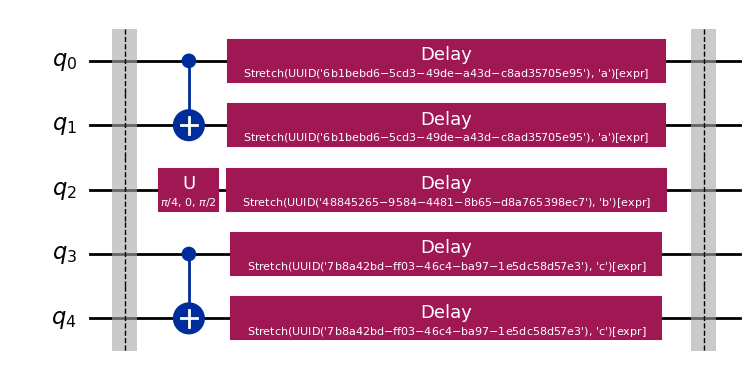

In [10]:
from qiskit import QuantumCircuit
from numpy import pi

qc = QuantumCircuit(5)

qc.barrier()

qc.cx(0, 1)
qc.u(pi/4, 0, pi/2, 2)
qc.cx(3, 4)

a = qc.add_stretch("a")
b = qc.add_stretch("b")
c = qc.add_stretch("c")

qc.delay(a, [0, 1])
qc.delay(b, 2)
qc.delay(c, [3, 4])

qc.barrier()
qc.draw("mpl")

In [11]:
from qiskit import QuantumCircuit

qc = QuantumCircuit(2)

# Synchronization boundary
qc.barrier()

# Operations on qubit 0
qc.h(0)
qc.cx(0, 1)

# Symbolic delay on qubit 1
s = qc.add_stretch("s")

qc.delay(s, 1)
qc.x(1)
qc.delay(s, 1)

# End synchronization boundary
qc.barrier()

print(qc)

      ░ ┌───┐     »
q_0: ─░─┤ H ├──■──»
      ░ └───┘┌─┴─┐»
q_1: ─░──────┤ X ├»
      ░      └───┘»
«                                                                                »
«q_0: ───────────────────────────────────────────────────────────────────────────»
«     ┌─────────────────────────────────────────────────────────────────────────┐»
«q_1: ┤ Delay(Stretch(UUID('16b74fa1-fe80-4002-b95a-156fc089a3ca'), 's')[expr]) ├»
«     └─────────────────────────────────────────────────────────────────────────┘»
«          »
«q_0: ─────»
«     ┌───┐»
«q_1: ┤ X ├»
«     └───┘»
«                                                                                »
«q_0: ───────────────────────────────────────────────────────────────────────────»
«     ┌─────────────────────────────────────────────────────────────────────────┐»
«q_1: ┤ Delay(Stretch(UUID('16b74fa1-fe80-4002-b95a-156fc089a3ca'), 's')[expr]) ├»
«     └─────────────────────────────────────────────────────────────────────────┘»
«    

Dynamical decoupling
A common use case of stretch is to apply dynamical decoupling to an idling qubit while another qubit is undergoing conditional operations.

For example, we can use stretch to apply an XX dynamical decoupling sequence to qubit 1, for the duration of the conditional block applied to qubit 0, as illustrated by the following diagram:

Image illustrating the following circuit
The corresponding circuit would look like the following. Note that a pair of barriers is needed to define the boundaries of this relative timing.

In [1]:
from qiskit.circuit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.circuit.classical import expr

qubits = QuantumRegister(2)
clbits = ClassicalRegister(2)
circuit = QuantumCircuit(qubits, clbits)
(q0, q1) = qubits
(c0, c1) = clbits

# Add barriers to define the boundaries
circuit.barrier()
circuit.h(q0)
circuit.measure(q0, c0)
with circuit.if_test((c0, 1)) as else_:
    circuit.h(q0)
with else_:
    circuit.x(q0)

# Apply an XX DD sequence with stretch on qubit 1
s = circuit.add_stretch("s")
circuit.delay(s, q1)
circuit.x(q1)
circuit.delay(expr.mul(s, 2), q1)
circuit.x(q1)
circuit.delay(s, q1)
circuit.barrier()

CircuitInstruction(operation=Instruction(name='barrier', num_qubits=2, num_clbits=0, params=[]), qubits=(<Qubit register=(2, "q0"), index=0>, <Qubit register=(2, "q0"), index=1>), clbits=())

In [2]:
from qiskit import QuantumCircuit
from numpy import pi

qc = QuantumCircuit(5)
qc.barrier()
qc.cx(0, 1)
qc.u(pi/4, 0, pi/2, 2)
qc.cx(3, 4)

a = qc.add_stretch("a")
b = qc.add_stretch("b")
c = qc.add_stretch("c")

# Use the stretches as Delay duration.
qc.delay(a, [0, 1])
qc.delay(b, 2)
qc.delay(c, [3, 4])
qc.barrier()


CircuitInstruction(operation=Instruction(name='barrier', num_qubits=5, num_clbits=0, params=[]), qubits=(<Qubit register=(5, "q"), index=0>, <Qubit register=(5, "q"), index=1>, <Qubit register=(5, "q"), index=2>, <Qubit register=(5, "q"), index=3>, <Qubit register=(5, "q"), index=4>), clbits=())

In [3]:
a = circuit.add_stretch("a")
circuit.barrier(q0, q1)
circuit.delay(100, q0)
circuit.delay(a, q1)  # resolve to 26
circuit.x(q1)  # duration: 8
circuit.delay(a, q1)  # resolve to 25
circuit.x(q1)  # duration: 8
circuit.delay(a, q1)  # resolve to 25
circuit.x(q1)  # duration: 8
circuit.barrier(q0, q1)

In [4]:
# Define the circuit
circuit = QuantumCircuit(4)
foo = circuit.add_stretch("foo")
bar = circuit.add_stretch("bar")
circuit.barrier()
circuit.cz(0, 1)
circuit.cz(0, 1)
circuit.cz(0, 1)
circuit.cz(0, 1)

circuit.delay(foo, 2)
circuit.x(2)
# 3*foo
circuit.delay(expr.mul(3, foo), 2)
circuit.x(2)
# 2*foo
circuit.delay(expr.mul(2, foo), 2)

circuit.delay(bar, 3)
circuit.x(3)
circuit.delay(bar, 3)

circuit.measure_all()

In [ ]:
qss = draw_circuit_schedule_timing(job.result()[0].metadata
    ['compilation']['scheduler_timing']['timing'])